### **Edge Detection**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jrafa1607/Computer_Vision_In_Python/blob/main/Algorithms/Edge_Detection.ipynb)

> Edges are places where the intensity changes sharply. They outline objects and are the starting point for segmentation and recognition. This notebook compares the **Roberts**, **Prewitt**, and **Sobel** gradient operators, the **Laplacian** (second derivative), and the multi-stage **Canny** detector.

In [1]:
# Import libraries and helpers (images load from ../Images locally, or from GitHub in Colab)
import os
import urllib.request

import cv2
import numpy as np
from matplotlib import pyplot as plt

BASE_URL = "https://raw.githubusercontent.com/jrafa1607/Computer_Vision_In_Python/main/Images/"

def load_image(name, flags=cv2.IMREAD_COLOR):
    """Returns the image in OpenCV format (BGR for color images)."""
    local = os.path.join("..", "Images", name)
    if os.path.exists(local):
        data = np.fromfile(local, np.uint8)
    else:
        with urllib.request.urlopen(BASE_URL + name) as response:
            data = np.frombuffer(response.read(), np.uint8)
    return cv2.imdecode(data, flags)

def show(images, titles, size=(14, 4)):
    """Shows images side by side; color images are converted from BGR to RGB for Matplotlib."""
    fig, axes = plt.subplots(1, len(images), figsize=size)
    for ax, image, title in zip(np.atleast_1d(axes), images, titles):
        if image.ndim == 3:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(image, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

In [2]:
# Load the image and convert it to grayscale
img = load_image("astronaut.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

#### **01. Gradient Operators**

Each operator estimates the horizontal (`Gx`) and vertical (`Gy`) derivatives with a pair of kernels. The edge strength is the **gradient magnitude** `sqrt(Gx² + Gy²)`.

| Operator | Kernel size | Characteristics |
| --- | :---: | --- |
| Roberts | 2×2 | Diagonal differences; simple, very sensitive to noise |
| Prewitt | 3×3 | Equal weights; detects horizontal and vertical edges |
| Sobel | 3×3 | Center weight 2; smooths while differentiating, less noisy |

The kernels produce **negative values** (dark-to-bright and bright-to-dark transitions have opposite signs), so the computation must use floating point. With 8-bit output, the negative half of every edge is clipped to zero.

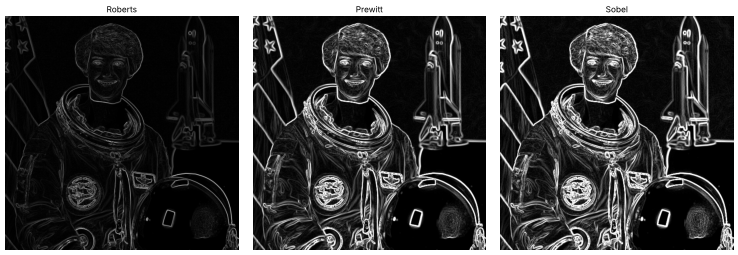

In [3]:
# Gradient magnitude for Roberts, Prewitt, and Sobel (computed in float)
def gradient_magnitude(image, kx, ky):
    image = image.astype(np.float32)
    gx = cv2.filter2D(image, cv2.CV_32F, kx)
    gy = cv2.filter2D(image, cv2.CV_32F, ky)
    return np.clip(np.sqrt(gx ** 2 + gy ** 2), 0, 255).astype(np.uint8)

roberts = gradient_magnitude(gray, np.array([[1, 0], [0, -1]], np.float32), np.array([[0, 1], [-1, 0]], np.float32))
prewitt = gradient_magnitude(gray, np.array([[-1, 0, 1]] * 3, np.float32), np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], np.float32))
sobel_x = cv2.Sobel(gray, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_32F, 0, 1, ksize=3)
sobel = np.clip(cv2.magnitude(sobel_x, sobel_y), 0, 255).astype(np.uint8)

show([roberts, prewitt, sobel], ["Roberts", "Prewitt", "Sobel"], size=(15, 5))

**The 8-bit pitfall:** with `ddepth=-1` (same type as the input), OpenCV saturates negative derivatives to 0, so only bright-to-dark transitions in one direction survive. Compare the two vertical-edge maps below.

Edge pixels above 50: 8-bit 29026 vs. float 58742


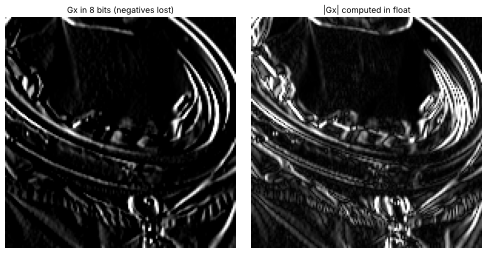

In [4]:
# Horizontal derivative in 8 bits (negatives clipped) vs. absolute value in float
gx_8bit = cv2.Sobel(gray, -1, 1, 0, ksize=3)
gx_float = np.clip(np.abs(sobel_x), 0, 255).astype(np.uint8)
crop = (slice(180, 330), slice(150, 300))
print(f"Edge pixels above 50: 8-bit {np.count_nonzero(gx_8bit > 50)} vs. float {np.count_nonzero(gx_float > 50)}")
show([gx_8bit[crop], gx_float[crop]], ["Gx in 8 bits (negatives lost)", "|Gx| computed in float"], size=(10, 5))

#### **02. Laplacian and Canny**

* **Laplacian:** second derivative; detects edges in all directions but amplifies noise, so it is usually applied after a Gaussian blur (**Laplacian of Gaussian**).
* **Canny:** Gaussian smoothing, gradient, non-maximum suppression (thin edges), and hysteresis with two thresholds. A common automatic choice sets the thresholds around the median intensity.

Canny thresholds: low=86, high=171


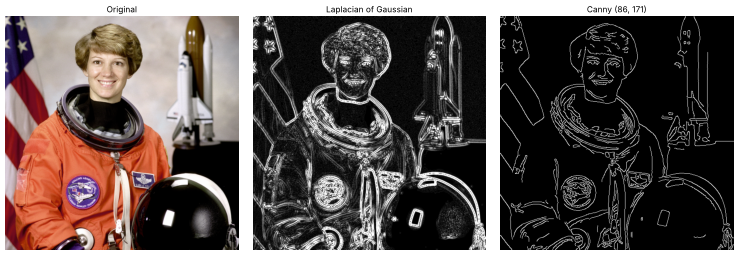

In [5]:
# Laplacian of Gaussian and Canny with automatic thresholds
blurred = cv2.GaussianBlur(gray, (5, 5), 0)
log = np.clip(np.abs(cv2.Laplacian(blurred, cv2.CV_32F, ksize=3)) * 4, 0, 255).astype(np.uint8)

median = np.median(gray)
low, high = int(max(0, 0.67 * median)), int(min(255, 1.33 * median))
canny = cv2.Canny(blurred, low, high)
print(f"Canny thresholds: low={low}, high={high}")
show([img, log, canny], ["Original", "Laplacian of Gaussian", f"Canny ({low}, {high})"], size=(15, 5))

#### **Key Takeaways**

* Combine `Gx` and `Gy` with the magnitude, not with an 8-bit addition.
* Smooth before second-derivative operators.
* Canny gives thin, connected edges and is the usual default for contour extraction.